<a href="https://colab.research.google.com/github/Simranpande/retail-demand-forecasting/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/retail-demand-forecasting/data/"
df = pd.read_parquet(BASE + "processed/m5_ca1_top100.parquet")

Mounted at /content/drive


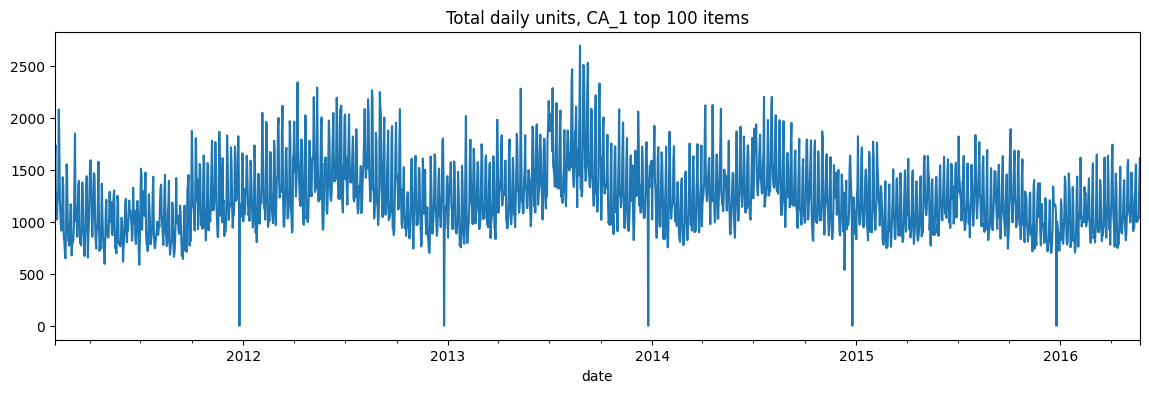

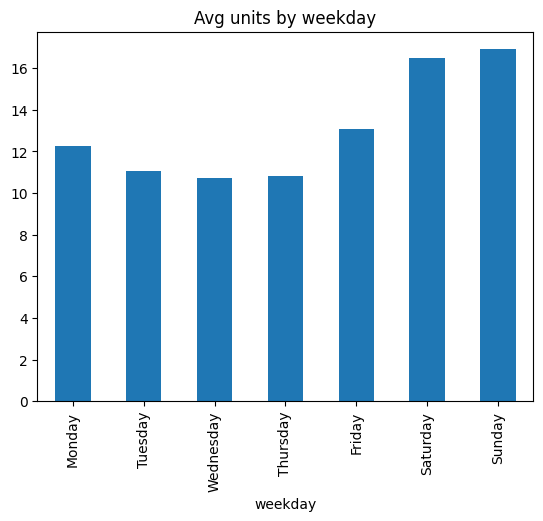

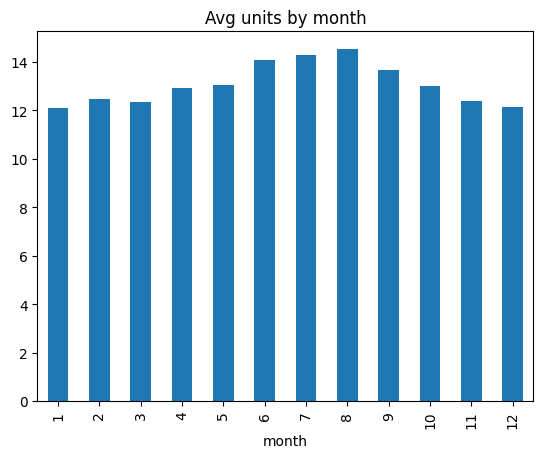

is_event
False    13.085408
True     12.627614
Name: units, dtype: float64


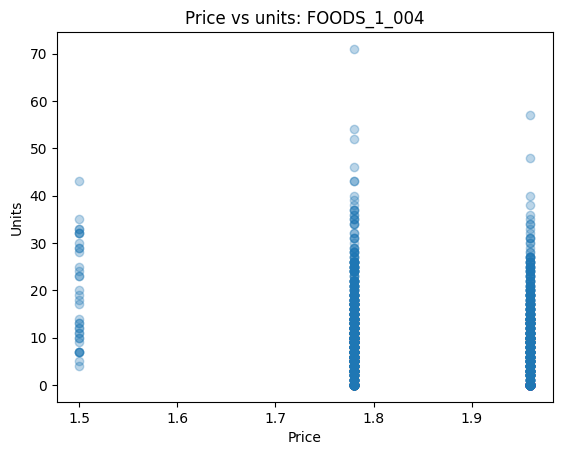

In [2]:
# 1. Total daily units over time (look for trend, yearly seasonality, gaps)
daily = df.groupby("date")["units"].sum()
daily.plot(figsize=(14, 4), title="Total daily units, CA_1 top 100 items")
plt.show()

# 2. Average units by weekday
df.groupby("weekday")["units"].mean().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
).plot(kind="bar", title="Avg units by weekday")
plt.show()

# 3. Average units by month
df.groupby("month")["units"].mean().plot(kind="bar", title="Avg units by month")
plt.show()

# 4. Event days vs normal days
df["is_event"] = df["event_name_1"] != "None"
print(df.groupby("is_event")["units"].mean())

# 5. Price vs units for one item (first elasticity hint)
item = df["item_id"].iloc[0]
sub = df[df["item_id"] == item]
plt.scatter(sub["sell_price"], sub["units"], alpha=0.3)
plt.xlabel("Price"); plt.ylabel("Units"); plt.title(f"Price vs units: {item}")
plt.show()